# Expérience 4 — Identification du dialecte et sentiment

**Question :** Un petit modèle spécialisé reconnaît-il mieux le dialecte d’une phrase qu’un grand LLM en zero/few-shot ?

**Métrique :** accuracy et F1 macro, plus la matrice de confusion.

**Résultat (à remplir à la fin) :**

## 0. Mise en place
Avant de lancer : ajouter le secret HF_TOKEN (icône 🔑) et avoir accès au dossier Drive darija_project. Le CPU suffit pour ce notebook.

In [1]:
import os, sys

REPO = "Ninessss/darija-llm"
BRANCH = "exp4/classification"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("/content/darija-llm"):
        !git clone -q -b {BRANCH} https://github.com/{REPO}.git /content/darija-llm
    %cd /content/darija-llm
    !git checkout -q {BRANCH} && git pull -q
    !echo "Commit utilisé : $(git rev-parse --short HEAD)"
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Dossier de travail :", os.getcwd())

from src.metrics import *
from src.normalize import normalize

/content/darija-llm
Commit utilisé : 3fbb1f4
Dossier de travail : /content/darija-llm


## 1. Données : MADAR (did.parquet)
4 classes : DZ (Alger), MA (Rabat, Fès), TN (Tunis, Sfax), MSA. Ce sont les mêmes phrases traduites dans chaque ville : le modèle apprend le dialecte, pas la source. Découpage officiel de MADAR, équilibré. Licence de recherche interne : aucune phrase n’est affichée dans ce notebook.

In [2]:
import pandas as pd
SEED = 42
from google.colab import drive
drive.mount('/content/drive')
DATA = "/content/drive/MyDrive/darija_project/data"

did = pd.read_parquet(f"{DATA}/processed/did.parquet")
print(did.shape)
print(pd.crosstab(did["split"], did["dialect"]))

# Vérification : une même phrase ne doit pas être à la fois dans train et test
g = did.groupby("group_id")["split"].nunique()
print("Phrases présentes dans plusieurs splits :", (g > 1).sum())

train = did[did["split"] == "train"]
val   = did[did["split"] == "val"]
test  = did[did["split"] == "test"]

Mounted at /content/drive
(7956, 16)
dialect    DZ    MA   MSA    TN
split                          
test      198   198   198   198
train    1591  1591  1591  1591
val       200   200   200   200
Phrases présentes dans plusieurs splits : 0


## 2. Représentation : TF-IDF sur les n-grammes de caractères
Des morceaux de 2 à 5 lettres plutôt que des mots entiers, car l’orthographe de la darija varie beaucoup. Le vectoriseur est appris sur le train uniquement.

In [3]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Calcul sur :", device)
from sklearn.feature_extraction.text import TfidfVectorizer

CLASSES = ["DZ", "MA", "TN", "MSA"]
lab2id = {c: i for i, c in enumerate(CLASSES)}

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=20000, sublinear_tf=True)
vec.fit(train["text"])                  # appris sur le train SEULEMENT

def to_tensors(part):
    X = torch.tensor(vec.transform(part["text"]).toarray(), dtype=torch.float32)
    y = torch.tensor(part["dialect"].map(lab2id).values, dtype=torch.long)
    return X, y

X_train, y_train = [t.to(device) for t in to_tensors(train)]
X_val, y_val     = [t.to(device) for t in to_tensors(val)]
X_test, y_test   = to_tensors(test)
X_test = X_test.to(device)          # y_test reste sur le processeur pour les scores
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([6364, 20000]) torch.Size([800, 20000]) torch.Size([792, 20000])


## 3. Baseline : régression logistique (nn.Linear)
Le modèle le plus simple, qui sert de point de comparaison. CrossEntropyLoss sur les logits bruts, sans softmax (cours 1, TP 1).

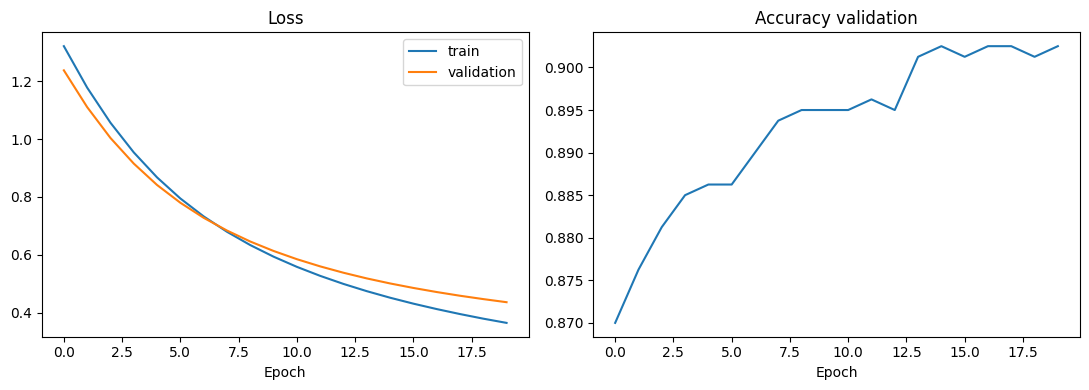

In [4]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(SEED)

def entrainer(model, epochs=20, lr=1e-3, batch_size=64):
    model.to(device)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    criterion = nn.CrossEntropyLoss()            # logits bruts, labels long, pas de softmax
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        hist["train_loss"].append(total / len(X_train))

        model.eval()
        with torch.no_grad():
            logits = model(X_val)
            hist["val_loss"].append(criterion(logits, y_val).item())
            hist["val_acc"].append((logits.argmax(1) == y_val).float().mean().item())
    return hist

baseline = nn.Linear(X_train.shape[1], len(CLASSES))   # une seule couche = régression logistique
hist = entrainer(baseline)

# Courbes : train et validation (pour repérer l'overfitting, cours 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["val_acc"]); ax[1].set_title("Accuracy validation"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.savefig("results/figures/exp4_madar_baseline_courbes.png", dpi=150); plt.show()

In [5]:
baseline.eval()
with torch.no_grad():
    pred = baseline(X_test).argmax(1).cpu()

res = classification_report(y_test.numpy(), pred.numpy())
print(f"Accuracy : {res['accuracy']:.3f}")
print(f"F1 macro : {res['f1_macro']:.3f}")
print("Matrice de confusion (lignes = vrai dialecte, colonnes = prédiction) :", CLASSES)
print(res["confusion"])

Accuracy : 0.894
F1 macro : 0.895
Matrice de confusion (lignes = vrai dialecte, colonnes = prédiction) : ['DZ', 'MA', 'TN', 'MSA']
[[177   6   7   8]
 [ 17 172   5   4]
 [  9   6 180   3]
 [ 14   2   3 179]]


### Essai : 60 epochs au lieu de 20
Vérifie si la baseline manque d’entraînement.

In [6]:
torch.manual_seed(SEED)
baseline_60 = nn.Linear(X_train.shape[1], len(CLASSES))
hist_60 = entrainer(baseline_60, epochs=60)
print("Accuracy validation finale (60 epochs) :", round(hist_60["val_acc"][-1], 3))

Accuracy validation finale (60 epochs) : 0.91


## 4. MLP et overfitting
Une couche cachée de 128 neurones. On observe l’overfitting : la loss de validation remonte alors que celle du train tend vers 0.

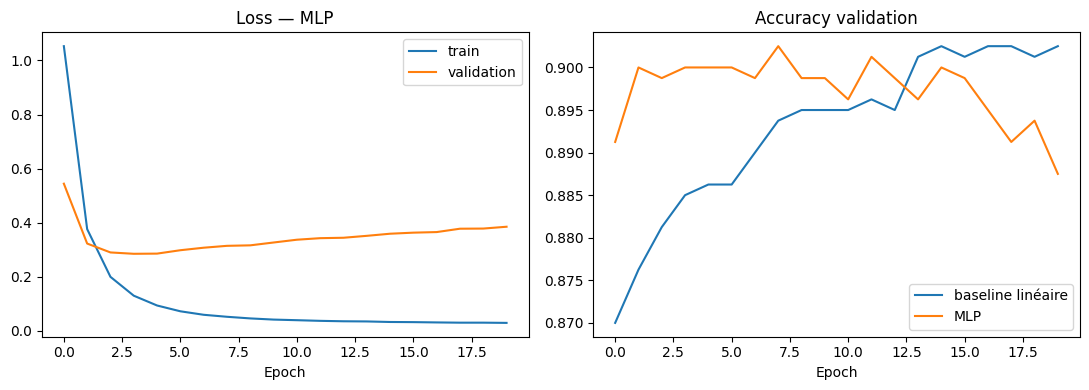

Accuracy validation finale — MLP : 0.887


In [7]:
torch.manual_seed(SEED)

mlp = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, len(CLASSES)),    # logits bruts, toujours pas de softmax
)
hist_mlp = entrainer(mlp, epochs=20)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_mlp["train_loss"], label="train"); ax[0].plot(hist_mlp["val_loss"], label="validation")
ax[0].set_title("Loss — MLP"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["val_acc"], label="baseline linéaire"); ax[1].plot(hist_mlp["val_acc"], label="MLP")
ax[1].set_title("Accuracy validation"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig("results/figures/exp4_madar_mlp_overfitting.png", dpi=150)
plt.show()
print("Accuracy validation finale — MLP :", round(hist_mlp["val_acc"][-1], 3))

### Arrêt anticipé et weight decay (cours 2)
On garde les poids de la meilleure epoch en validation, et on teste 3 valeurs de weight decay.

In [8]:
import copy

def entrainer_v2(model, epochs=20, lr=1e-3, batch_size=64, weight_decay=0.0):
    model.to(device)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    meilleur_acc, meilleurs_poids, meilleure_epoch = -1, None, -1

    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        hist["train_loss"].append(total / len(X_train))

        model.eval()
        with torch.no_grad():
            logits = model(X_val)
            acc = (logits.argmax(1) == y_val).float().mean().item()
            hist["val_loss"].append(criterion(logits, y_val).item())
            hist["val_acc"].append(acc)
        if acc > meilleur_acc:                       # early stopping : on retient la meilleure epoch
            meilleur_acc, meilleure_epoch = acc, epoch
            meilleurs_poids = copy.deepcopy(model.state_dict())

    model.load_state_dict(meilleurs_poids)           # on repart des meilleurs poids
    print(f"Meilleure epoch : {meilleure_epoch}, accuracy validation : {meilleur_acc:.3f}")
    return hist

resultats = {}
for wd in [0.0, 0.01, 0.1]:
    torch.manual_seed(SEED)
    mlp = nn.Sequential(nn.Linear(X_train.shape[1], 128), nn.ReLU(), nn.Linear(128, len(CLASSES)))
    print(f"--- weight decay = {wd}")
    resultats[wd] = (mlp, entrainer_v2(mlp, weight_decay=wd))

--- weight decay = 0.0
Meilleure epoch : 7, accuracy validation : 0.902
--- weight decay = 0.01
Meilleure epoch : 7, accuracy validation : 0.902
--- weight decay = 0.1
Meilleure epoch : 7, accuracy validation : 0.902


In [ ]:
mlp_final = resultats[0.0][0]          # le MLP sans weight decay, avec les poids de la meilleure epoch
mlp_final.eval()
with torch.no_grad():
    pred = mlp_final(X_test).argmax(1).cpu()

res = classification_report(y_test.numpy(), pred.numpy())
print(f"Accuracy : {res['accuracy']:.3f}")
print(f"F1 macro : {res['f1_macro']:.3f}")
print("Matrice de confusion :", CLASSES)
print(res["confusion"])

## 5. Comparaison équitable sur 3 seeds
Baseline et MLP entraînés de la même façon (AdamW et arrêt anticipé), avec 3 seeds, pour savoir si l’écart est réel.

In [ ]:
import numpy as np

def score_test(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test).argmax(1).cpu()
    r = classification_report(y_test.numpy(), pred.numpy())
    return r["accuracy"], r["f1_macro"]

SEEDS = [42, 43, 44]
scores = {"baseline": [], "mlp": []}

for s in SEEDS:
    torch.manual_seed(s)
    base = nn.Linear(X_train.shape[1], len(CLASSES))
    entrainer_v2(base, epochs=20)
    scores["baseline"].append(score_test(base))

    torch.manual_seed(s)
    mlp = nn.Sequential(nn.Linear(X_train.shape[1], 128), nn.ReLU(), nn.Linear(128, len(CLASSES)))
    entrainer_v2(mlp, epochs=20, weight_decay=0.0)
    scores["mlp"].append(score_test(mlp))

for nom, liste in scores.items():
    acc = np.array([a for a, f in liste]); f1 = np.array([f for a, f in liste])
    print(f"{nom:9s} accuracy {acc.mean():.3f} ± {acc.std():.3f} | F1 macro {f1.mean():.3f} ± {f1.std():.3f} | par seed : {np.round(acc, 3)}")

## 6. Validation des hyperparamètres du MLP
On change un seul réglage à la fois (profondeur, largeur, activation, learning rate), et on compare sur la validation avec 3 seeds.

In [ ]:
import matplotlib.pyplot as plt

def make_mlp(depth=1, width=128, act=nn.ReLU):
    couches, d_in = [], X_train.shape[1]
    for _ in range(depth):
        couches += [nn.Linear(d_in, width), act()]
        d_in = width
    couches.append(nn.Linear(d_in, len(CLASSES)))
    return nn.Sequential(*couches)

def score_val(config, seeds=(42, 43, 44)):
    accs = []
    for s in seeds:
        torch.manual_seed(s)
        m = make_mlp(config["depth"], config["width"], config["act"])
        h = entrainer_v2(m, epochs=20, lr=config["lr"])
        accs.append(max(h["val_acc"]))          # accuracy de la meilleure epoch
    return np.mean(accs), np.std(accs)

REF = {"depth": 1, "width": 128, "act": nn.ReLU, "lr": 1e-3}
GRILLE = {
    "Profondeur (couches cachées)": ("depth", [1, 2, 3]),
    "Largeur (neurones)":           ("width", [32, 64, 128, 256]),
    "Activation":                   ("act",   [nn.ReLU, nn.ELU, nn.SiLU]),
    "Learning rate":                ("lr",    [1e-4, 1e-3, 1e-2]),
}

resultats_variantes = {}
for titre, (cle, valeurs) in GRILLE.items():
    resultats_variantes[titre] = []
    for v in valeurs:
        config = {**REF, cle: v}
        moy, ecart = score_val(config)
        nom = v.__name__ if cle == "act" else str(v)
        resultats_variantes[titre].append((nom, moy, ecart))
        print(f"{titre} = {nom} : {moy:.3f} ± {ecart:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (titre, res) in zip(axes, resultats_variantes.items()):
    noms = [r[0] for r in res]; moys = [r[1] for r in res]; ecarts = [r[2] for r in res]
    ax.bar(noms, moys, yerr=ecarts, capsize=4)
    ax.set_title(titre); ax.set_ylim(0.85, 0.92)
axes[0].set_ylabel("Accuracy validation (3 seeds)")
plt.tight_layout()
plt.savefig("results/figures/exp4_variantes_mlp.png", dpi=150)
plt.show()

Meilleure epoch : 7, accuracy validation : 0.902
Meilleure epoch : 3, accuracy validation : 0.904
Meilleure epoch : 5, accuracy validation : 0.906
Profondeur (couches cachées) = 1 : 0.904 ± 0.002
Meilleure epoch : 18, accuracy validation : 0.895
Meilleure epoch : 12, accuracy validation : 0.897
Meilleure epoch : 3, accuracy validation : 0.897
Profondeur (couches cachées) = 2 : 0.897 ± 0.001
Meilleure epoch : 14, accuracy validation : 0.897
Meilleure epoch : 6, accuracy validation : 0.901
Meilleure epoch : 13, accuracy validation : 0.899
Profondeur (couches cachées) = 3 : 0.899 ± 0.002
Meilleure epoch : 4, accuracy validation : 0.906
Meilleure epoch : 13, accuracy validation : 0.906
Meilleure epoch : 5, accuracy validation : 0.905
Largeur (neurones) = 32 : 0.906 ± 0.001
Meilleure epoch : 6, accuracy validation : 0.908
Meilleure epoch : 10, accuracy validation : 0.906
Meilleure epoch : 6, accuracy validation : 0.905
Largeur (neurones) = 64 : 0.906 ± 0.001
Meilleure epoch : 7, accuracy va

## 7. Analyse des erreurs : matrice de confusion
Quels dialectes le modèle confond-il ? Pour une machine, est-ce la même darija ?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

baseline.eval()
with torch.no_grad():
    pred = baseline(X_test).argmax(1).cpu()
cm = classification_report(y_test.numpy(), pred.numpy())["confusion"]

noms = ["Algérien (DZ)", "Marocain (MA)", "Tunisien (TN)", "Arabe standard (MSA)"]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(noms, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(noms)
ax.set_xlabel("Dialecte prédit"); ax.set_ylabel("Vrai dialecte")
ax.set_title("Matrice de confusion — baseline, MADAR (test)")
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig("results/figures/exp4_madar_confusion.png", dpi=150)
plt.show()